# Figure 3b. PsychAD trans-eQTL precision and recall

This panel compares fine-mapped and colocalization-supported trans-eQTL variants in six matched PsychAD cell contexts. Recall is the fraction of PsychAD variants with $p < 10^{-5}$ found by each method. Precision is conditional on variants reported in PsychAD at $p < 0.001$ across all six contexts; its numerator is cell-type matched, but its denominator is pooled across contexts. It is not the fraction of all method discoveries independently replicated. Genes are not matched, microglia are compared with the broader PsychAD Immune category, and chromosome 17 is excluded. Error bars are 95% leave-one-chromosome-out jackknife intervals.

Input: `data/Figure_3b_psychad_precision_recall.rds` (12 plot-ready summary rows).

In [1]:
suppressPackageStartupMessages(library(ggplot2))
d <- readRDS("data/Figure_3b_psychad_precision_recall.rds")
stopifnot(nrow(d) == 12L, all(d$scope == "celltype_matched_exclude_chr17"),
          all(d$recall_ci_low_pct <= d$recall_pct & d$recall_pct <= d$recall_ci_high_pct),
          all(d$precision_ci_low_pct <= d$precision_pct & d$precision_pct <= d$precision_ci_high_pct))
d[, c("context", "method", "recall_pct", "precision_pct")]

Warning message:
"package 'ggplot2' was built under R version 4.4.3"


context,method,recall_pct,precision_pct
<fct>,<fct>,<dbl>,<dbl>
Ast,Fine-mapped trans-eQTL hits,0.4149378,12.654321
Ast,Colocalized trans-eQTL,6.3859933,9.315028
Exc,Fine-mapped trans-eQTL hits,0.4173187,8.586762
Exc,Colocalized trans-eQTL,4.6426708,11.651756
Inh,Fine-mapped trans-eQTL hits,0.3230097,8.740360
Inh,Colocalized trans-eQTL,6.1371841,10.031056
Mic,Fine-mapped trans-eQTL hits,0.2868904,9.236948
Mic,Colocalized trans-eQTL,5.5382313,8.442670
Oli,Fine-mapped trans-eQTL hits,0.3557513,10.659898


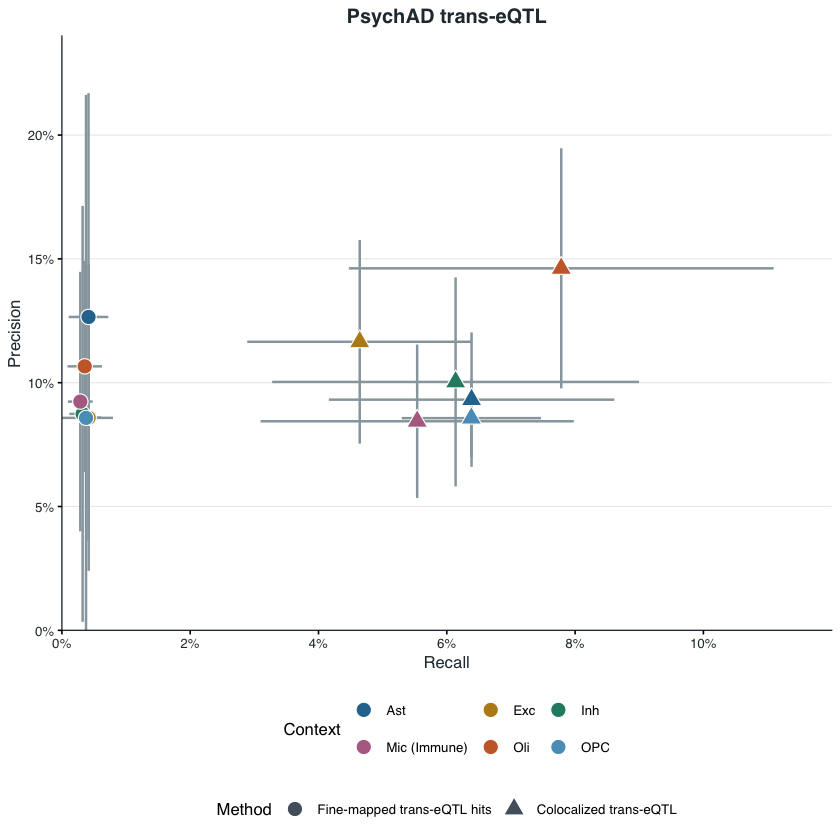

In [2]:
context_colors <- c(Ast = "#2A759E", Exc = "#B98B19", Inh = "#258A73",
                    Mic = "#B56F91", Oli = "#CA6936", OPC = "#5A9EC3")
method_shapes <- c("Fine-mapped trans-eQTL hits" = 21,
                   "Colocalized trans-eQTL" = 24)
p <- ggplot(d) +
  geom_hline(yintercept = c(5, 10, 15, 20), color = "#E8ECEE", linewidth = 0.32) +
  geom_segment(aes(x = recall_ci_low_pct, xend = recall_ci_high_pct,
                   y = precision_pct, yend = precision_pct),
               color = "#98A5AC", linewidth = 0.7) +
  geom_segment(aes(x = recall_pct, xend = recall_pct,
                   y = precision_ci_low_pct, yend = precision_ci_high_pct),
               color = "#98A5AC", linewidth = 0.7) +
  geom_point(aes(x = recall_pct, y = precision_pct, fill = context, shape = method),
             size = 4, stroke = 0.48, color = "white") +
  scale_fill_manual(values = context_colors,
                    labels = c("Ast", "Exc", "Inh", "Mic (Immune)", "Oli", "OPC"),
                    name = "Context") +
  scale_shape_manual(values = method_shapes, name = "Method") +
  scale_x_continuous(limits = c(0, 12), breaks = seq(0, 10, 2),
                     labels = function(x) paste0(x, "%"), expand = expansion(mult = c(0, 0))) +
  scale_y_continuous(limits = c(0, 24), breaks = c(0, 5, 10, 15, 20),
                     labels = function(y) paste0(y, "%"), expand = expansion(mult = c(0, 0))) +
  labs(title = "PsychAD trans-eQTL", x = "Recall", y = "Precision") +
  guides(fill = guide_legend(order = 1, nrow = 2, byrow = TRUE,
                             override.aes = list(shape = 21, color = "white")),
         shape = guide_legend(order = 2, nrow = 1,
                              override.aes = list(fill = "#52616C", color = "white"))) +
  theme_classic(base_size = 10, base_family = "sans") +
  theme(axis.line = element_line(linewidth = 0.38, color = "#27363E"),
        axis.text = element_text(color = "#27363E"),
        axis.title = element_text(color = "#27363E"),
        plot.title = element_text(face = "bold", hjust = 0.5, color = "#27363E"),
        legend.position = "bottom", legend.box = "vertical")
print(p)